In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv("../Data/creditcard_clean.csv")
print(data.shape)
data.head()

(283726, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-0.995290,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,1.774718,0
1,-0.995290,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.268530,0
2,-0.995279,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,4.959811,0
3,-0.995279,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,1.411487,0
4,-0.995267,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0.667362,0


## 1. Class distribution

In [4]:
counts = data["Class"].value_counts()
percent = data["Class"].value_counts(normalize=True) * 100

print(counts)
print(percent.round(3))

Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.833
1     0.167
Name: proportion, dtype: float64


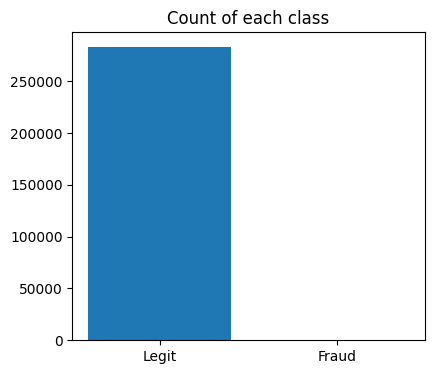

In [5]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.bar(["Legit", "Fraud"], counts)
plt.title("Count of each class")


plt.show()

In [6]:
# accuracy of a model that always predicts legit
print("Always-legit accuracy:", round(counts[0] / len(data) * 100, 2), "%")

Always-legit accuracy: 99.83 %


**Class imbalance:** fraud is a tiny part of the data. A model that always says "legit" gets very high accuracy but catches no fraud, so accuracy is misleading. We use precision, recall and F1-score instead.

## 2. Amount: fraud vs legit

Amount is already scaled, so values can be negative and are not real money. That is fine for comparing the two classes.

In [7]:
data.groupby("Class")["Amount"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,0.924,3.482,-0.306,-0.227,0.000,0.771,356.962
1,473.0,1.417,3.619,-0.306,-0.292,-0.169,1.167,29.257


Median - legit: 0.0
Median - fraud: -0.169


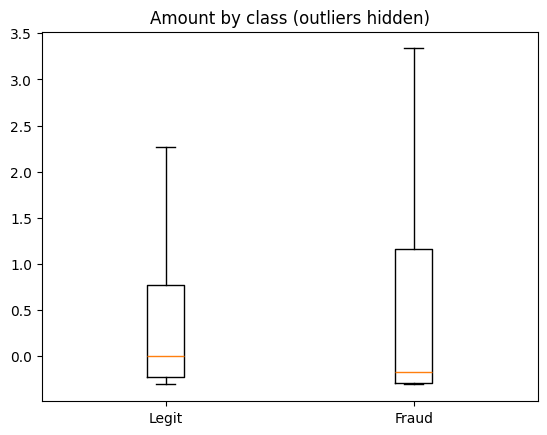

In [8]:
legit = data[data["Class"] == 0]["Amount"]
fraud = data[data["Class"] == 1]["Amount"]

print("Median - legit:", round(legit.median(), 3))
print("Median - fraud:", round(fraud.median(), 3))

plt.boxplot([legit, fraud], showfliers=False)
plt.xticks([1, 2], ["Legit", "Fraud"])
plt.title("Amount by class (outliers hidden)")
plt.show()

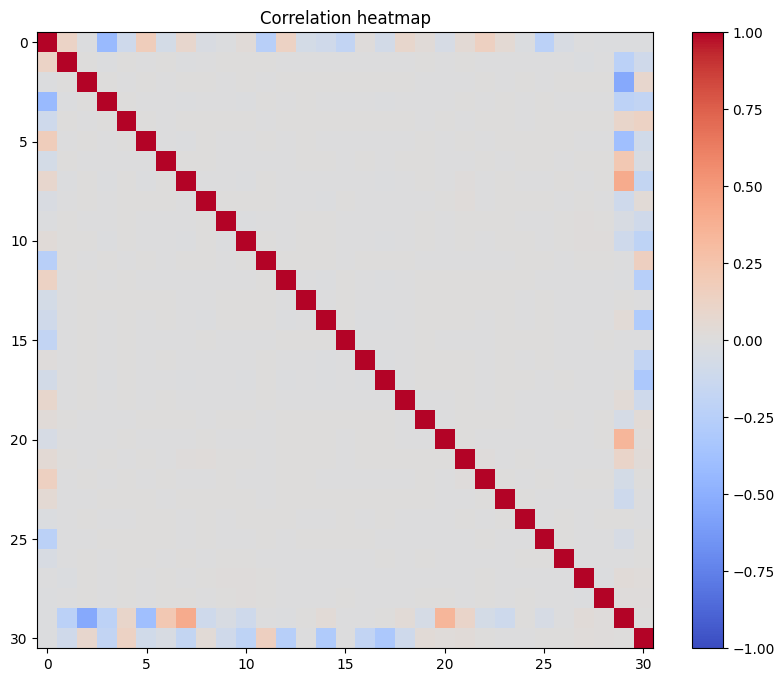

In [9]:
corr = data.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.title("Correlation heatmap")
plt.show()

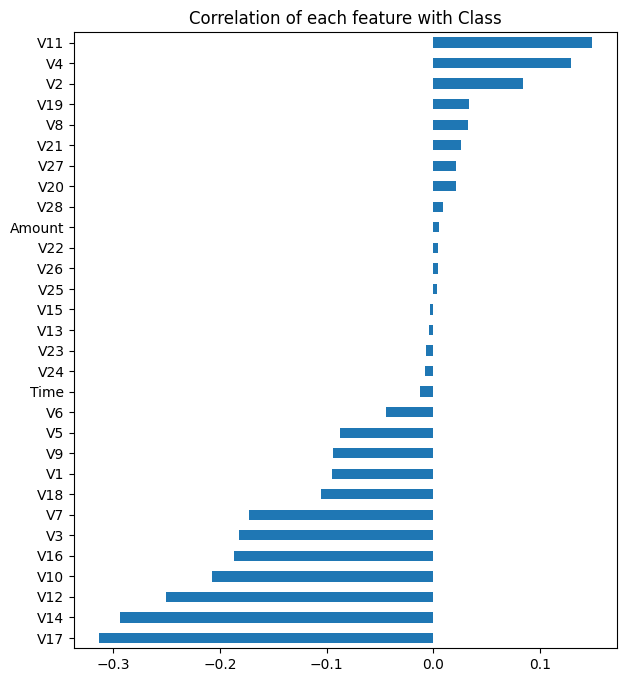

Top 6 features: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']


In [10]:
corr_class = corr["Class"].drop("Class").sort_values()

plt.figure(figsize=(7, 8))
corr_class.plot(kind="barh")
plt.title("Correlation of each feature with Class")
plt.show()

top6 = corr_class.abs().sort_values(ascending=False).head(6).index.tolist()
print("Top 6 features:", top6)

## 4. Top features: fraud vs legit

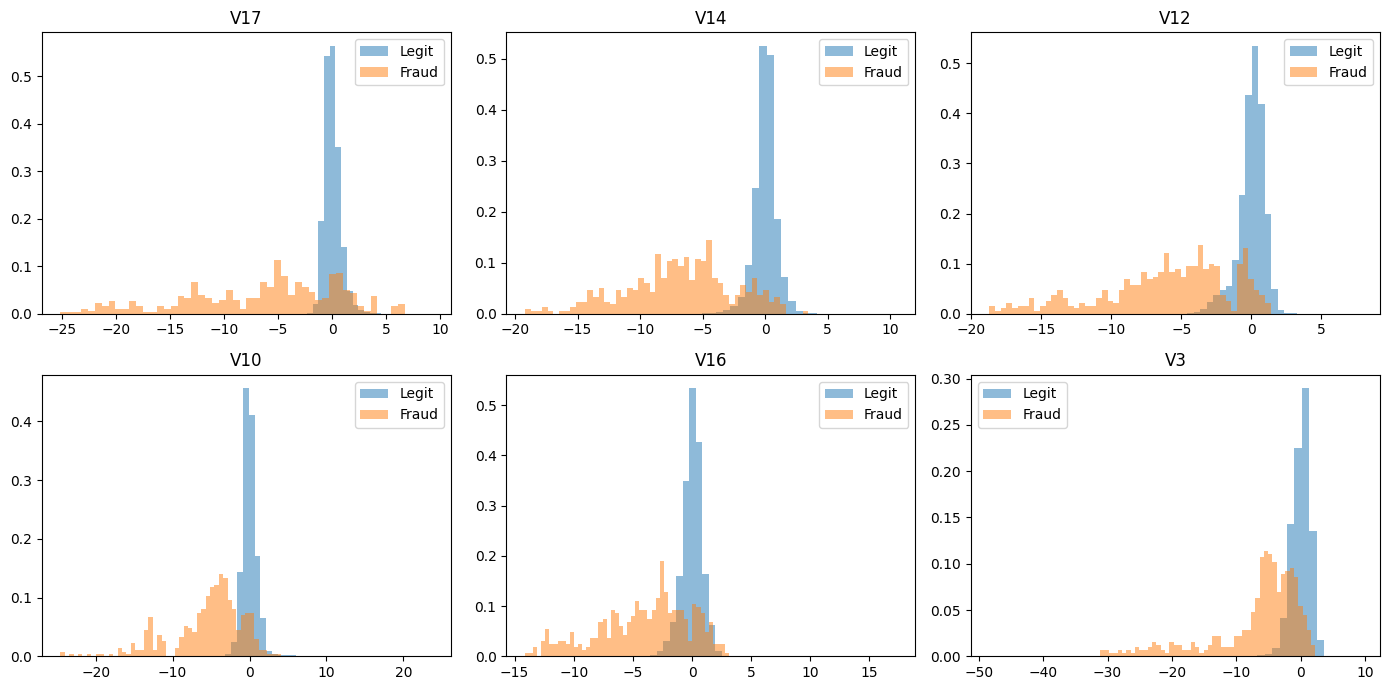

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for ax, f in zip(axes, top6):
    ax.hist(data[data["Class"] == 0][f], bins=50, alpha=0.5, density=True, label="Legit")
    ax.hist(data[data["Class"] == 1][f], bins=50, alpha=0.5, density=True, label="Fraud")
    ax.set_title(f)
    ax.legend()

plt.tight_layout()
plt.show()